Taller Repaso Tema 2 

In [1]:
# Librerías permitidas por el taller: NumPy, Matplotlib y scikit-learn
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (confusion_matrix, accuracy_score,
                             precision_score, recall_score, f1_score)

SEED = 42                     # semilla fija para todo el cuaderno
np.random.seed(SEED)
plt.rcParams["figure.dpi"] = 110

In [2]:
# ---- 1.1: verificación numérica y gráfica de la frontera ----
w = np.array([1.0, 2.0])
b = -3.0

def predecir(X, w, b):
    # Regla del enunciado: +1 si w^T x + b > 0, y -1 si es <= 0
    return np.where(X @ w + b > 0, 1, -1)

X_pts = np.array([[0, 0], [1, 0], [2, 1], [3, 1]], dtype=float)
f_vals = X_pts @ w + b          # valor de w^T x + b para cada punto
y_hat = predecir(X_pts, w, b)

for i, (x, f, yh) in enumerate(zip(X_pts, f_vals, y_hat), start=1):
    print(f"x{i} = {tuple(x.tolist())}  ->  w^T x + b = {f:+.0f}  ->  y_hat = {yh:+d}")

x1 = (0.0, 0.0)  ->  w^T x + b = -3  ->  y_hat = -1
x2 = (1.0, 0.0)  ->  w^T x + b = -2  ->  y_hat = -1
x3 = (2.0, 1.0)  ->  w^T x + b = +1  ->  y_hat = +1
x4 = (3.0, 1.0)  ->  w^T x + b = +2  ->  y_hat = +1


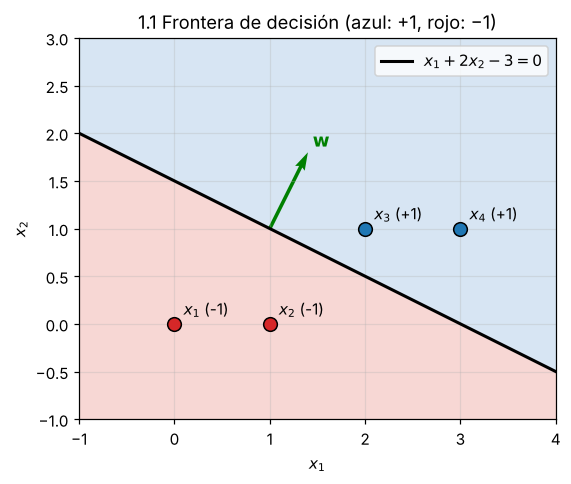

In [3]:
# Gráfica: recta x2 = (3 - x1)/2, regiones coloreadas y los 4 puntos
x1_grid = np.linspace(-1, 4, 300)
x2_recta = (3 - x1_grid) / 2

xx, yy = np.meshgrid(np.linspace(-1, 4, 300), np.linspace(-1, 3, 300))
Z = predecir(np.c_[xx.ravel(), yy.ravel()], w, b).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.contourf(xx, yy, Z, levels=[-2, 0, 2], colors=["#f4c7c3", "#c6dbef"], alpha=0.7)
ax.plot(x1_grid, x2_recta, "k-", lw=2, label=r"$x_1 + 2x_2 - 3 = 0$")

for i, (x, yh) in enumerate(zip(X_pts, y_hat), start=1):
    ax.scatter(*x, c="tab:blue" if yh == 1 else "tab:red", s=80, edgecolor="k", zorder=3)
    ax.annotate(f"$x_{i}$ ({yh:+d})", x, textcoords="offset points", xytext=(6, 6))

# vector w dibujado desde un punto de la recta (normal a la frontera)
ax.quiver(1, 1, w[0], w[1], angles="xy", scale_units="xy", scale=2.5, color="green")
ax.text(1.45, 1.85, r"$\mathbf{w}$", color="green", fontsize=12)

ax.set_xlim(-1, 4); ax.set_ylim(-1, 3); ax.set_aspect("equal")
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
ax.set_title("1.1 Frontera de decisión (azul: +1, rojo: −1)")
ax.legend(loc="upper right"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("fig_1_1_frontera.png", dpi=200); plt.show()

In [4]:
# ---- 1.2: comprobación numérica de la identidad con valores aleatorios ----
rng = np.random.default_rng(SEED)
for prueba in range(5):
    w_r, b_r = rng.normal(size=2), rng.normal()
    x_r, y_r = rng.normal(size=2), rng.choice([-1, 1])
    eta = rng.uniform(0.1, 2)

    m_antes = y_r * (w_r @ x_r + b_r)
    w_n, b_n = w_r + eta * y_r * x_r, b_r + eta * y_r      # regla de actualización
    m_despues = y_r * (w_n @ x_r + b_n)                     # margen calculado directamente
    m_formula = m_antes + eta * (x_r @ x_r + 1)             # margen según la fórmula demostrada

    print(f"prueba {prueba}: directo = {m_despues:+.6f} | fórmula = {m_formula:+.6f} | "
          f"iguales: {np.isclose(m_despues, m_formula)}")

prueba 0: directo = +11.865640 | fórmula = +11.865640 | iguales: True
prueba 1: directo = +2.003095 | fórmula = +2.003095 | iguales: True
prueba 2: directo = +1.780489 | fórmula = +1.780489 | iguales: True
prueba 3: directo = +2.109996 | fórmula = +2.109996 | iguales: True
prueba 4: directo = +2.725934 | fórmula = +2.725934 | iguales: True


In [5]:
# ---- 1.3: mismo cálculo en código ----
w0, b0, eta = np.array([0.0, 0.0]), 0.0, 0.5
x, y = np.array([2.0, 1.0]), +1

f0 = w0 @ x + b0
y_hat0 = 1 if f0 > 0 else -1
m0 = y * f0
print(f"w^T x + b = {f0}  ->  y_hat = {y_hat0},  margen m = {m0}")

if y_hat0 != y:                      # mal clasificado -> se actualiza
    w1 = w0 + eta * y * x
    b1 = b0 + eta * y
    m1 = y * (w1 @ x + b1)
    print(f"Se actualiza: w_nuevo = {w1}, b_nuevo = {b1}")
    print(f"Margen nuevo (directo)  = {m1}")
    print(f"Margen nuevo (fórmula)  = {m0 + eta * (x @ x + 1)}")
    print(f"Nueva predicción: {1 if w1 @ x + b1 > 0 else -1}")

w^T x + b = 0.0  ->  y_hat = -1,  margen m = 0.0
Se actualiza: w_nuevo = [1.  0.5], b_nuevo = 0.5
Margen nuevo (directo)  = 3.0
Margen nuevo (fórmula)  = 3.0
Nueva predicción: 1


In [6]:
# ---- 2.1: verificación de distancias y votaciones ----
q = np.array([1.0, 1.0])
X_tr = np.array([[0, 0], [1, 0], [3, 1], [0, 3], [1.1, 1.1]])
y_tr = np.array(["A", "A", "B", "B", "B"])
nombres = np.array(["x1", "x2", "x3", "x4", "x5"])

d = np.sqrt(((X_tr - q) ** 2).sum(axis=1))   # distancia euclidiana a cada punto
orden = np.argsort(d)                        # índices de menor a mayor distancia

print("Orden (más cercano -> más lejano):")
for i in orden:
    print(f"  {nombres[i]} {tuple(X_tr[i].tolist())}  clase {y_tr[i]}  d = {d[i]:.4f}")

# votación mayoritaria implementada a mano
for k in [1, 3, 5]:
    vecinos = y_tr[orden[:k]]
    clases, votos = np.unique(vecinos, return_counts=True)
    print(f"k={k}: vecinos {nombres[orden[:k]].tolist()} -> votos {dict(zip(clases.tolist(), votos.tolist()))} "
          f"-> predicción {clases[np.argmax(votos)]}")

# misma verificación con scikit-learn
for k in [1, 3, 5]:
    knn = KNeighborsClassifier(n_neighbors=k).fit(X_tr, y_tr)
    print(f"scikit-learn, k={k}: {knn.predict([q])[0]}")

Orden (más cercano -> más lejano):
  x5 (1.1, 1.1)  clase B  d = 0.1414
  x2 (1.0, 0.0)  clase A  d = 1.0000
  x1 (0.0, 0.0)  clase A  d = 1.4142
  x3 (3.0, 1.0)  clase B  d = 2.0000
  x4 (0.0, 3.0)  clase B  d = 2.2361
k=1: vecinos ['x5'] -> votos {'B': 1} -> predicción B
k=3: vecinos ['x5', 'x2', 'x1'] -> votos {'A': 2, 'B': 1} -> predicción A
k=5: vecinos ['x5', 'x2', 'x1', 'x3', 'x4'] -> votos {'A': 2, 'B': 3} -> predicción B
scikit-learn, k=1: B
scikit-learn, k=3: A
scikit-learn, k=5: B


In [7]:
# ---- 2.2: datos, partición y entrenamiento ----
X, y = make_moons(n_samples=300, noise=0.20, random_state=SEED)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED)

print(f"Entrenamiento: {X_train.shape[0]} obs. | clases {np.bincount(y_train)}")
print(f"Prueba:        {X_test.shape[0]} obs. | clases {np.bincount(y_test)}")

ks = [1, 5, 15]
modelos, resultados = {}, []
for k in ks:
    knn = KNeighborsClassifier(n_neighbors=k)        # distancia euclidiana por defecto
    knn.fit(X_train, y_train)                        # k-NN "aprende" guardando los datos
    acc_tr = accuracy_score(y_train, knn.predict(X_train))
    acc_te = accuracy_score(y_test,  knn.predict(X_test))
    modelos[k] = knn
    resultados.append((k, acc_tr, acc_te))

print("\n  k | Exactitud entrenamiento | Exactitud prueba")
print("----+-------------------------+-----------------")
for k, a_tr, a_te in resultados:
    print(f"{k:3d} | {a_tr:23.4f} | {a_te:16.4f}")

Entrenamiento: 210 obs. | clases [105 105]
Prueba:        90 obs. | clases [45 45]

  k | Exactitud entrenamiento | Exactitud prueba
----+-------------------------+-----------------
  1 |                  1.0000 |           0.9333
  5 |                  0.9571 |           0.9556
 15 |                  0.9571 |           0.9333


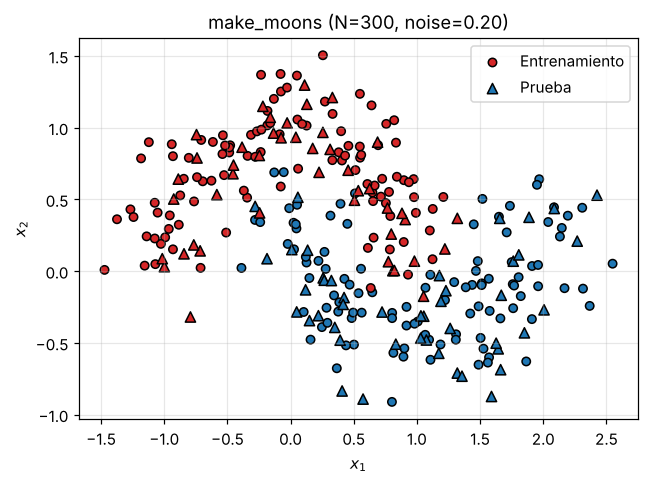

In [8]:
# Datos generados, separados por partición
cm_pts = ListedColormap(["#d62728", "#1f77b4"])
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=cm_pts, edgecolor="k", s=30, label="Entrenamiento")
ax.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap=cm_pts, marker="^", edgecolor="k", s=45, label="Prueba")
ax.set_title("make_moons (N=300, noise=0.20)")
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("fig_2_2_datos.png", dpi=200); plt.show()

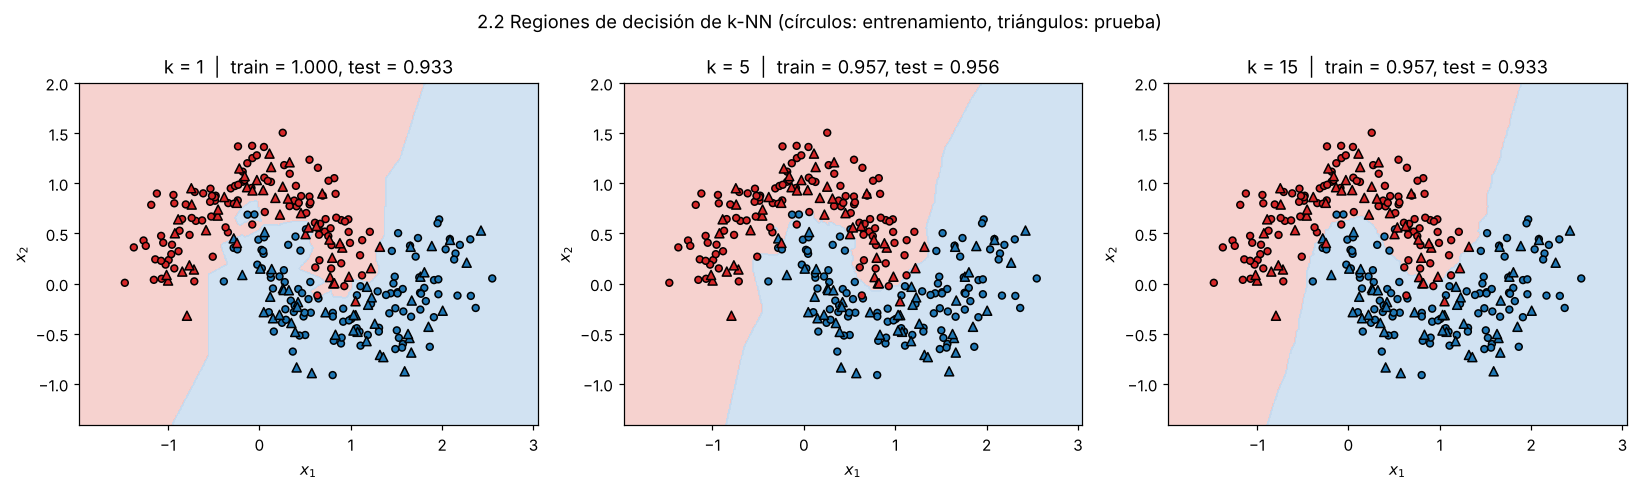

In [9]:
# Regiones de decisión: se predice la clase en una malla fina que cubre el plano
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 400), np.linspace(y_min, y_max, 400))
malla = np.c_[xx.ravel(), yy.ravel()]
cm_reg = ListedColormap(["#f4c7c3", "#c6dbef"])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (k, a_tr, a_te) in zip(axes, resultados):
    Z = modelos[k].predict(malla).reshape(xx.shape)
    ax.contourf(xx, yy, Z, cmap=cm_reg, alpha=0.8)
    ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=cm_pts, edgecolor="k", s=20)
    ax.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap=cm_pts, marker="^", edgecolor="k", s=35)
    ax.set_title(f"k = {k}  |  train = {a_tr:.3f}, test = {a_te:.3f}")
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
plt.suptitle("2.2 Regiones de decisión de k-NN (círculos: entrenamiento, triángulos: prueba)")
plt.tight_layout(); plt.savefig("fig_2_2_regiones.png", dpi=200); plt.show()

Discusión: Al comparar los tres modelos, la exactitud de entrenamiento es de 1.000 con k = 1 y baja a 0.957 con k = 5 y k = 15. Esto pasa porque con k = 1 cada punto de entrenamiento es su propio vecino más cercano, así que el modelo siempre lo clasifica bien y esa exactitud no dice nada sobre su capacidad de generalizar. En prueba los tres modelos quedaron muy cerca: 0.933 para k = 1, 0.956 para k = 5 y 0.933 para k = 15. Con 90 observaciones de prueba, la diferencia entre ellos es de apenas 2 puntos mal clasificados.

En las regiones de decisión, con k = 1 la frontera es muy irregular y forma pequeñas islas alrededor de puntos ruidosos que quedaron metidos en la luna contraria. Con k = 5 la frontera ya sigue la forma curva de las lunas sin reaccionar a cada punto aislado. Con k = 15 se vuelve todavía más suave y rígida, y en la zona central donde las dos clases se solapan empieza a perder algo de detalle. En los tres casos los errores se concentran justamente en esa zona de cruce, que es donde el ruido (noise = 0.20) mezcla las clases y ningún valor de k puede separarlas por completo.

Por último, la estratificación dejó exactamente 45 puntos por clase en prueba, así que la exactitud no está sesgada hacia ninguna clase y es una medida razonable para este caso.

### 2.3 Interpretación

- **$k$ muy pequeño ($k=1$):** cada punto de entrenamiento es su propio vecino más cercano, por eso la exactitud de entrenamiento
  es 1.0. La frontera es muy irregular y forma "islas" alrededor de puntos ruidosos: el modelo memoriza el ruido
  (**sobreajuste**, baja sesgo y alta varianza).
- **$k$ muy grande:** la votación se hace sobre vecindarios amplios y la frontera se vuelve suave. Si $k$ crece demasiado
  (en el límite, $k$ igual al número de datos de entrenamiento) el modelo predice siempre la clase mayoritaria
  (**subajuste**, alto sesgo).
- **Resultados obtenidos:** $k=1$ tiene exactitud 1.000 en entrenamiento pero 0.933 en prueba (brecha de 6.7 puntos, señal de sobreajuste).
  $k=15$ tiene 0.957 / 0.933: frontera más suave, pero ya pierde algo de detalle en la zona donde las lunas se cruzan.
  **$k=5$ generalizó mejor**: obtuvo la mayor exactitud de prueba (0.956) y prácticamente no tiene brecha con
  entrenamiento (0.957), lo que indica un buen equilibrio entre sesgo y varianza. Con solo 90 puntos de prueba,
  una diferencia de 0.022 equivale a 2 observaciones, así que la ventaja es pequeña.
- **¿Por qué validar y no usar la prueba?** El conjunto de prueba debe ser una estimación imparcial del desempeño con datos
  nunca vistos. Si se escoge $k$ mirando la exactitud de prueba, esa partición pasa a formar parte del entrenamiento
  (se ajusta un hiperparámetro con ella) y la exactitud reportada queda optimista. Lo correcto es elegir $k$ con
  validación cruzada sobre el conjunto de entrenamiento (por ejemplo `GridSearchCV` con 5 pliegues) y usar la prueba
  una sola vez, al final.

In [10]:
# Selección automática del mejor modelo en la evaluación de prueba (solo para reportarlo)
mejor = max(resultados, key=lambda r: (r[2], -abs(r[1] - r[2])))
for k, a_tr, a_te in resultados:
    print(f"k={k:2d}: brecha entrenamiento - prueba = {a_tr - a_te:+.4f}")
print(f"\nMejor exactitud de prueba: k = {mejor[0]} ({mejor[2]:.4f})")

k= 1: brecha entrenamiento - prueba = +0.0667
k= 5: brecha entrenamiento - prueba = +0.0016
k=15: brecha entrenamiento - prueba = +0.0238

Mejor exactitud de prueba: k = 5 (0.9556)


k elegido por validación cruzada (5 pliegues): 11  (exactitud CV = 0.9619)


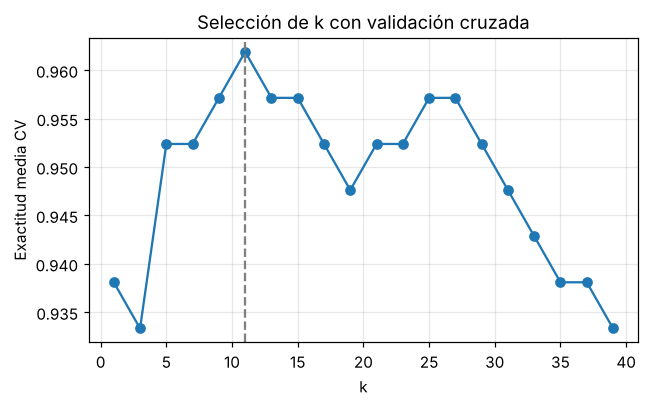

In [11]:
# Ilustración de la selección correcta de k: validación cruzada SOLO con el conjunto de entrenamiento
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
k_rango = range(1, 41, 2)
cv_media = [cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train, y_train, cv=cv).mean()
            for k in k_rango]
k_cv = list(k_rango)[int(np.argmax(cv_media))]
print(f"k elegido por validación cruzada (5 pliegues): {k_cv}  (exactitud CV = {max(cv_media):.4f})")

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(list(k_rango), cv_media, "o-")
ax.axvline(k_cv, color="gray", ls="--")
ax.set_xlabel("k"); ax.set_ylabel("Exactitud media CV"); ax.grid(alpha=0.3)
ax.set_title("Selección de k con validación cruzada")
plt.tight_layout(); plt.savefig("fig_2_3_cv.png", dpi=200); plt.show()

In [12]:
# ---- 3.3: verificación con scikit-learn ----
y_true = np.array([0, 0, 0, 0, 1, 1, 1, 1, 1, 1])
y_pred = np.array([0, 1, 0, 0, 1, 0, 1, 1, 0, 1])

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])   # filas: real, columnas: predicho
tn, fp, fn, tp = cm.ravel()                            # orden de ravel() para el caso binario
print("Matriz de confusión:\n", cm)
print(f"TP={tp}, TN={tn}, FP={fp}, FN={fn}\n")

metricas = {
    "Accuracy":  (accuracy_score(y_true, y_pred),               7/10),
    "Precision": (precision_score(y_true, y_pred, pos_label=1), 4/5),
    "Recall":    (recall_score(y_true, y_pred, pos_label=1),    4/6),
    "F1":        (f1_score(y_true, y_pred, pos_label=1),        8/11),
}
print(f"{'Métrica':10s} {'sklearn':>8s} {'manual':>8s}  coincide")
for nombre, (sk, man) in metricas.items():
    print(f"{nombre:10s} {sk:8.4f} {man:8.4f}  {np.isclose(sk, man)}")

Matriz de confusión:
 [[3 1]
 [2 4]]
TP=4, TN=3, FP=1, FN=2

Métrica     sklearn   manual  coincide
Accuracy     0.7000   0.7000  True
Precision    0.8000   0.8000  True
Recall       0.6667   0.6667  True
F1           0.7273   0.7273  True


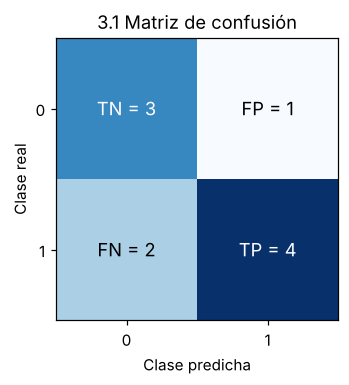

In [13]:
# Visualización de la matriz de confusión
fig, ax = plt.subplots(figsize=(4, 3.6))
ax.imshow(cm, cmap="Blues")
etq = [["TN", "FP"], ["FN", "TP"]]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{etq[i][j]} = {cm[i, j]}", ha="center", va="center",
                color="white" if cm[i, j] > 2 else "black", fontsize=12)
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xlabel("Clase predicha"); ax.set_ylabel("Clase real")
ax.set_title("3.1 Matriz de confusión")
plt.tight_layout(); plt.savefig("fig_3_cm.png", dpi=200); plt.show()

In [14]:
# Ejemplo numérico de por qué la exactitud puede engañar: datos desbalanceados
y_desb = np.array([0] * 95 + [1] * 5)       # 95 % negativos, 5 % positivos
y_trivial = np.zeros(100, dtype=int)        # "modelo" que siempre predice 0
print(f"Accuracy = {accuracy_score(y_desb, y_trivial):.2f}")
print(f"Recall   = {recall_score(y_desb, y_trivial, zero_division=0):.2f}")
print(f"F1       = {f1_score(y_desb, y_trivial, zero_division=0):.2f}")

Accuracy = 0.95
Recall   = 0.00
F1       = 0.00


### 3.3 Situaciones en las que la exactitud sola puede engañar

1. **Clases desbalanceadas.** Si 95 de cada 100 casos son negativos (por ejemplo, transacciones fraudulentas o una
   enfermedad rara), un modelo que siempre responde "negativo" obtiene 95 % de exactitud sin detectar ni un solo
   positivo (recall = 0, como muestra la celda anterior). La exactitud queda dominada por la clase mayoritaria.
2. **Costos de error distintos.** En tamizaje médico un falso negativo (no detectar a un paciente enfermo) es mucho más
   grave que un falso positivo; en un filtro de spam pasa lo contrario, porque mandar un correo importante a spam (FP)
   molesta más que dejar pasar un spam (FN). Dos modelos con la misma exactitud pueden repartir sus errores de forma
   muy diferente, y la exactitud no lo muestra; hay que mirar recall, precisión o la matriz de confusión.

En este ejercicio, la exactitud de 0.70 esconde que el modelo deja escapar un tercio de los positivos (recall ≈ 0.67),
mientras que cuando predice positivo acierta el 80 % de las veces.